In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [35]:
df = pd.read_csv("retail_sales.csv")

In [36]:
df

,Date,Product,Category,Price,Quantity Sold,Total Sales
0,2026-01-05,Laptop,Electronics,50000,2,100000
1,2026-01-08,Mobile,Electronics,20000,5,100000
2,2026-01-12,Headphones,Accessories,1500,10,15000
3,2026-01-15,Keyboard,Accessories,1000,8,8000
4,2026-01-18,Mobile,Electronics,20000,3,60000
5,2026-01-22,Monitor,Electronics,12000,4,48000
6,2026-01-25,Laptop,Electronics,50000,1,50000
7,2026-01-28,Mouse,Accessories,500,15,7500
8,2026-01-30,Tablet,Electronics,15000,3,45000
9,2026-02-03,Headphones,Accessories,1500,12,18000


In [37]:
len(df)

50

In [38]:
df.head()


,Date,Product,Category,Price,Quantity Sold,Total Sales
0,2026-01-05,Laptop,Electronics,50000,2,100000
1,2026-01-08,Mobile,Electronics,20000,5,100000
2,2026-01-12,Headphones,Accessories,1500,10,15000
3,2026-01-15,Keyboard,Accessories,1000,8,8000
4,2026-01-18,Mobile,Electronics,20000,3,60000


In [39]:
df.columns

Index(['Date', 'Product', 'Category', 'Price', 'Quantity Sold', 'Total Sales'],
      dtype='str')

In [40]:
required_columns = ["Date",
                     "Product",
                     "Category",
                     "Price",
                     "Quantity Sold",
                     "Total Sales"]

all(column in df.columns for column in required_columns)

True

In [99]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           50 non-null     datetime64[us]
 1   Product        50 non-null     str           
 2   Category       50 non-null     str           
 3   Price          50 non-null     int64         
 4   Quantity Sold  50 non-null     int64         
 5   Total Sales    50 non-null     int64         
dtypes: datetime64[us](1), int64(3), str(2)
memory usage: 2.5 KB


In [43]:
df.isnull().sum()

Date             0
Product          0
Category         0
Price            0
Quantity Sold    0
Total Sales      0
dtype: int64

In [44]:
df.describe()

,Price,Quantity Sold,Total Sales
count,50.000000,50.000000,50.00000
mean,15100.000000,7.000000,48930.00000
std,17012.600372,5.322267,44560.43935
min,500.000000,1.000000,5000.00000
25%,1000.000000,3.000000,10875.00000
50%,12000.000000,5.000000,42500.00000
75%,20000.000000,9.750000,74250.00000
max,50000.000000,25.000000,200000.00000


In [45]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

In [46]:
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

In [47]:
df["Quantity Sold"] = pd.to_numeric(df["Quantity Sold"], errors="coerce")

In [48]:
df["Total Sales"] = pd.to_numeric(df["Total Sales"], errors="coerce")

In [49]:
df.isnull().sum()

Date             0
Product          0
Category         0
Price            0
Quantity Sold    0
Total Sales      0
dtype: int64

In [50]:
df["Product"] = df["Product"].fillna("Unknown")

In [51]:
df["Category"] = df["Category"].fillna("Unknown")

In [52]:
df["Price"] = df["Price"].fillna(df["Price"].median())

In [53]:
df["Quantity Sold"] = df["Quantity Sold"].fillna(0)

In [54]:
df["Total Sales"] = df["Total Sales"].fillna(0)

In [55]:
df.head()

,Date,Product,Category,Price,Quantity Sold,Total Sales
0,2026-01-05,Laptop,Electronics,50000,2,100000
1,2026-01-08,Mobile,Electronics,20000,5,100000
2,2026-01-12,Headphones,Accessories,1500,10,15000
3,2026-01-15,Keyboard,Accessories,1000,8,8000
4,2026-01-18,Mobile,Electronics,20000,3,60000


In [56]:
for index, row in df.iterrows():
    if row["Price"] < 0 or row["Quantity Sold"] < 0:
        print("Invalid data found at row:", index)
    elif row["Price"] == 0 or row["Quantity Sold"] == 0:
        print("Warning: Zero price or quantity at row:", index)

print("Data validation completed!")

Data validation completed!


In [57]:
for category in df["Category"].unique():
    print("Category:", category)

Category: Electronics
Category: Accessories


In [58]:
sales_array = np.array(df["Total Sales"])

In [59]:
quantity_array = np.array(df["Quantity Sold"])

In [60]:
price_array = np.array(df["Price"])

In [61]:
sales_array

array([100000, 100000,  15000,   8000,  60000,  48000,  50000,   7500,
        45000,  18000,  80000,  10000,  60000, 100000,  10000,  60000,
         9000,  40000,   7000, 150000,  24000,   5000,  75000, 120000,
        12000,  12000,  50000,  36000,   9000,  30000,  80000,  22500,
       100000,   5000,  72000,  12500,  45000, 140000,  13500, 200000,
         9000,  48000,   6000,  90000,  60000,  10500, 100000,  15000,
        60000,   7000])

In [62]:
np.sum(sales_array)

np.int64(2446500)

In [63]:
np.mean(sales_array)

np.float64(48930.0)

In [64]:
np.max(sales_array)

np.int64(200000)

In [65]:
np.min(sales_array)

np.int64(5000)

In [66]:
np.sum(quantity_array)

np.int64(350)

In [67]:
np.mean(price_array)

np.float64(15100.0)

In [68]:
daily_sales = df.groupby("Date")["Total Sales"].sum().sort_index()

In [69]:
daily_sales

Date
2026-01-05    100000
2026-01-08    100000
2026-01-12     15000
2026-01-15      8000
2026-01-18     60000
2026-01-22     48000
2026-01-25     50000
2026-01-28      7500
2026-01-30     45000
2026-02-03     18000
2026-02-06     80000
2026-02-09     10000
2026-02-12     60000
2026-02-15    100000
2026-02-18     10000
2026-02-21     60000
2026-02-24      9000
2026-02-27     40000
2026-03-02      7000
2026-03-05    150000
2026-03-08     24000
2026-03-11      5000
2026-03-14     75000
2026-03-17    120000
2026-03-20     12000
2026-03-23     12000
2026-03-26     50000
2026-03-29     36000
2026-04-02      9000
2026-04-05     30000
2026-04-08     80000
2026-04-11     22500
2026-04-14    100000
2026-04-17      5000
2026-04-20     72000
2026-04-23     12500
2026-04-26     45000
2026-04-29    140000
2026-05-02     13500
2026-05-05    200000
2026-05-08      9000
2026-05-11     48000
2026-05-14      6000
2026-05-17     90000
2026-05-20     60000
2026-05-23     10500
2026-05-26    100000
2026-05-

In [70]:
if len(daily_sales) >= 2:
    first_sales = daily_sales.iloc[0]
    last_sales = daily_sales.iloc[-1]

    if first_sales != 0:
        growth = ((last_sales - first_sales) / first_sales) * 100
        print("Sales Growth Percentage:", round(growth, 2), "%")
    else:
        print("Initial sales are zero.")
else:
    print("Not enough dates to calculate growth.")

Sales Growth Percentage: -93.0 %


In [71]:
class RetailAnalyzer:
    def __init__(self, data):
        self.data = data.copy()

In [72]:
def load_data(self):
        print("Dataset loaded successfully!")
        print("Total records:", len(self.data))
        print("Total columns:", len(self.data.columns))

In [73]:
def calculate_metrics(self):
        total_sales = self.data["Total Sales"].sum()
        average_sales = self.data["Total Sales"].mean()
        total_quantity = self.data["Quantity Sold"].sum()

        return total_sales, average_sales, total_quantity

In [98]:
def filter_data(self, category):
        filtered_data = self.data[self.data["Category"].str.lower() == category.lower()]
        return filtered_data

In [75]:
def display_summary(self):
        print("RETAIL SALES SUMMARY")
        print("--------------------")
        print("Total Sales:", self.data["Total Sales"].sum())
        print("Total Transactions:", len(self.data))
        print("Total Quantity Sold:", self.data["Quantity Sold"].sum())

In [76]:
class RetailAnalyzer:
    def __init__(self, data):
        self.data = data.copy()

    def load_data(self):
        print("Dataset loaded successfully!")
        print("Total records:", len(self.data))
        print("Total columns:", len(self.data.columns))

    def calculate_metrics(self):
        total_sales = self.data["Total Sales"].sum()
        average_sales = self.data["Total Sales"].mean()
        total_quantity = self.data["Quantity Sold"].sum()
        return total_sales, average_sales, total_quantity

    def filter_data(self, category):
        filtered_data = self.data[
            self.data["Category"].str.lower() == category.lower()
        ]
        return filtered_data

    def display_summary(self):
        print("RETAIL SALES SUMMARY")
        print("--------------------")
        print("Total Sales:", self.data["Total Sales"].sum())
        print("Total Transactions:", len(self.data))
        print("Total Quantity Sold:", self.data["Quantity Sold"].sum())

In [77]:
analyzer = RetailAnalyzer(df)

In [78]:
analyzer.load_data()

Dataset loaded successfully!
Total records: 50
Total columns: 6


In [79]:
total_sales, average_sales, total_quantity = analyzer.calculate_metrics()

print("Total Sales:", total_sales)
print("Average Sales:", round(average_sales, 2))
print("Total Quantity Sold:", total_quantity)

Total Sales: 2446500
Average Sales: 48930.0
Total Quantity Sold: 350


In [80]:
df["Category"].unique()

<StringArray>
['Electronics', 'Accessories']
Length: 2, dtype: str

In [100]:
filtered_data = analyzer.filter_data("Electronics")
filtered_data

,Date,Product,Category,Price,Quantity Sold,Total Sales
0,2026-01-05,Laptop,Electronics,50000,2,100000
1,2026-01-08,Mobile,Electronics,20000,5,100000
4,2026-01-18,Mobile,Electronics,20000,3,60000
5,2026-01-22,Monitor,Electronics,12000,4,48000
6,2026-01-25,Laptop,Electronics,50000,1,50000
8,2026-01-30,Tablet,Electronics,15000,3,45000
10,2026-02-06,Mobile,Electronics,20000,4,80000
12,2026-02-12,Monitor,Electronics,12000,5,60000
13,2026-02-15,Laptop,Electronics,50000,2,100000
15,2026-02-21,Tablet,Electronics,15000,4,60000


In [82]:
analyzer.display_summary()

RETAIL SALES SUMMARY
--------------------
Total Sales: 2446500
Total Transactions: 50
Total Quantity Sold: 350


In [83]:
category_sales = df.groupby("Category")["Total Sales"].sum()

In [84]:
category_sales

Category
Accessories     223500
Electronics    2223000
Name: Total Sales, dtype: int64

In [85]:
df.groupby("Category")["Quantity Sold"].sum()

Category
Accessories    247
Electronics    103
Name: Quantity Sold, dtype: int64

In [86]:
df.groupby("Product")["Quantity Sold"].sum().sort_values(ascending=False)

Product
Mouse         114
Headphones     67
Keyboard       66
Mobile         34
Monitor        29
Tablet         23
Laptop         17
Name: Quantity Sold, dtype: int64

In [87]:
category_sales = df.groupby("Category")["Total Sales"].sum()

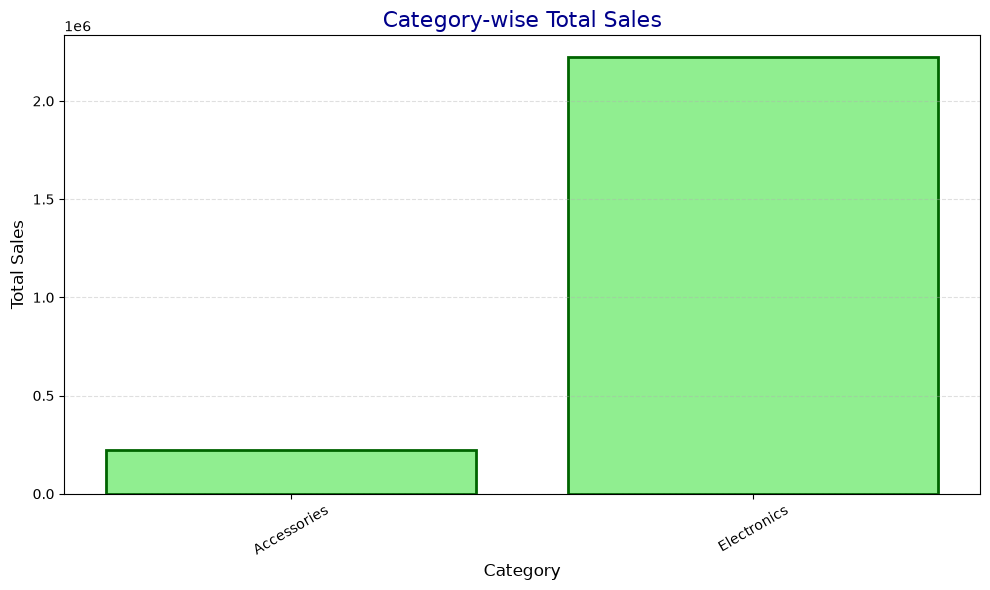

In [93]:
plt.figure(figsize=(10, 6))

plt.bar(category_sales.index,
        category_sales.values,
        color="lightgreen",
        edgecolor="darkgreen",
        linewidth=2)

plt.title("Category-wise Total Sales", fontsize=16, color="darkblue")
plt.xlabel("Category", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)

plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [90]:
daily_sales = df.groupby("Date")["Total Sales"].sum().sort_index()

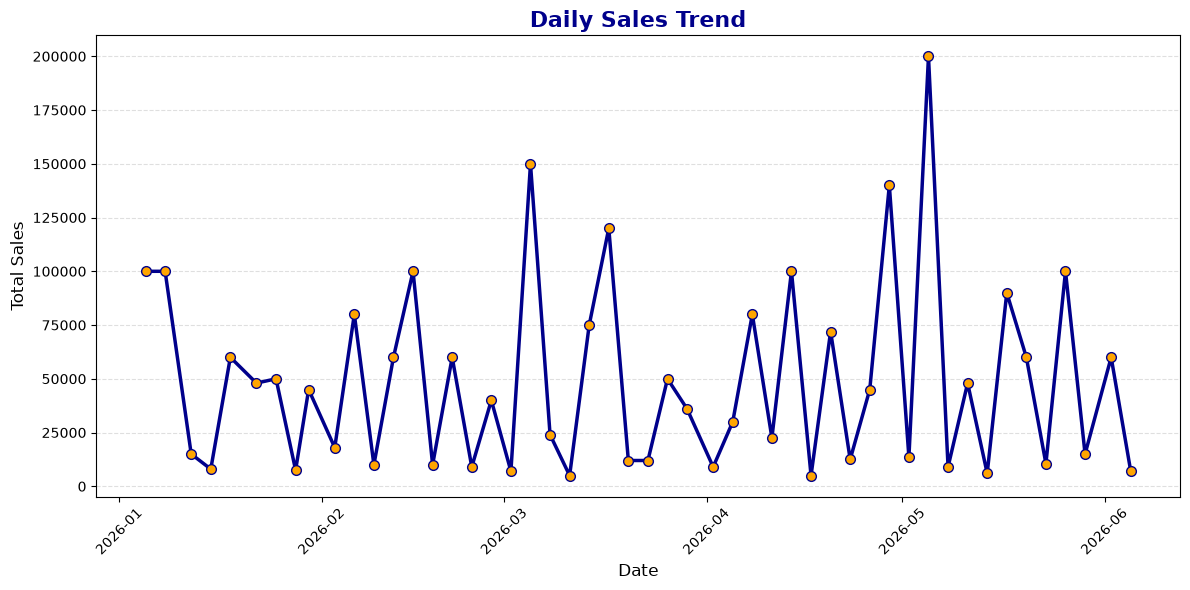

In [92]:
plt.figure(figsize=(12, 6))

plt.plot(daily_sales.index,
         daily_sales.values,
        color="darkblue",
        marker="o",
        markersize=7,
        markerfacecolor="orange",
        markeredgecolor="darkblue",
        linewidth=2.5,
        linestyle="-")

plt.title("Daily Sales Trend", fontsize=16, color="darkblue", fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)

plt.xticks(rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [94]:
numeric_data = df[["Price", "Quantity Sold", "Total Sales"]]

In [95]:
correlation = numeric_data.corr()

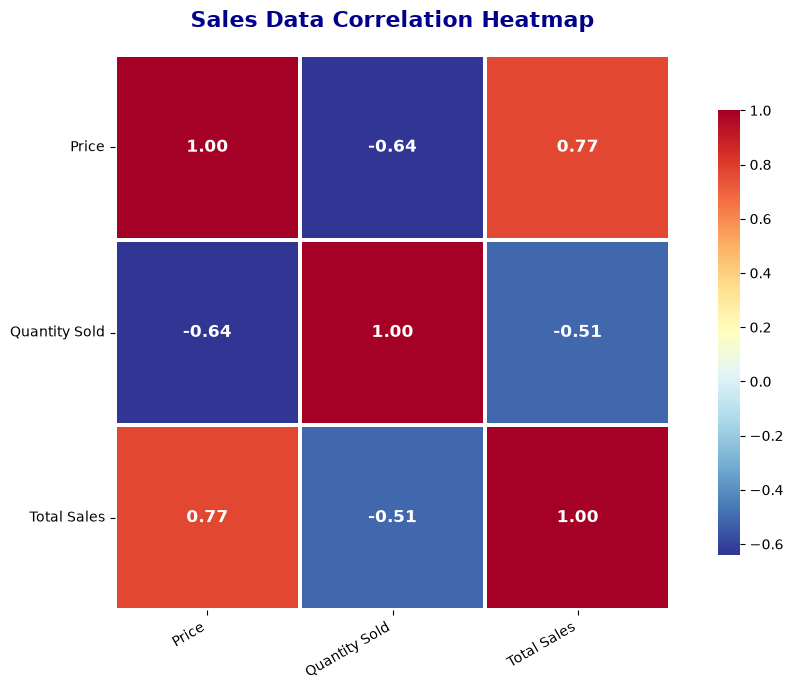

In [96]:
plt.figure(figsize=(10, 7))

sns.heatmap(correlation,
            annot=True,
            cmap="RdYlBu_r",
            fmt=".2f",
            linewidths=1.5,
            linecolor="white",
            annot_kws={"size": 12, "weight": "bold"},
            cbar_kws={"shrink": 0.8},
            square=True)

plt.title("Sales Data Correlation Heatmap",
          fontsize=16,
          color="darkblue",
          fontweight="bold",
          pad=20)

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [97]:
print("========== RETAIL SALES ANALYZER ==========")
print("Total Records:", len(df))
print("Total Sales:", round(df["Total Sales"].sum(), 2))
print("Average Sales:", round(df["Total Sales"].mean(), 2))
print("Total Quantity Sold:", df["Quantity Sold"].sum())
print("Number of Categories:", df["Category"].nunique())
print("Number of Products:", df["Product"].nunique())
print("===========================================")

========== RETAIL SALES ANALYZER ==========
Total Records: 50
Total Sales: 2446500
Average Sales: 48930.0
Total Quantity Sold: 350
Number of Categories: 2
Number of Products: 7
